# Экзаменационная задача №13. Оценка риска переплаты на аукционе (проклятие победителя)

**Дисциплина:** Экономика информатизации, лекция №14
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №13: ОЦЕНКА РИСКА ПЕРЕПЛАТЫ НА АУКЦИОНЕ (ПРОКЛЯТИЕ ПОБЕДИТЕЛЯ)
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №14)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Компания участвует в аукционе за стартап. Настоящая стоимость стартапа для всех одна (аукцион с **общей ценностью**),
но точно её никто не знает, каждый оценивает с ошибкой. Выигрывает тот, кто оценил выше всех, а это чаще всего тот,
кто сильнее всех **переоценил**. Это и есть **проклятие победителя**: сама победа говорит, что ваша оценка, скорее всего, завышена.

**Цель:** оценить вероятность и средний размер переплаты, построить распределение переплаты и понять, насколько
нужно снизить ставку.

Тема лекции №14: проклятие победителя, аукционы с общей ценностью, $E[\max X_i] - V > 0$, байесовская поправка ставки.

## 2. Исходные данные

In [2]:
V_low, V_high = 50, 150     # истинная стоимость ~ U[50; 150] млн руб.
n = 5                       # участников
sigma = 20                  # стандартная ошибка оценки, млн руб.
x_own = 100                 # наша оценка, млн руб.
N_sim = 200_000             # испытаний Монте-Карло
rng = np.random.default_rng(2026)
pd.DataFrame({"Параметр": ["Истинная стоимость V", "Участников n", "Ошибка оценки σ", "Наша оценка X"],
              "Значение": ["U[50; 150] млн руб.", n, f"{sigma} млн руб.", f"{x_own} млн руб."]})

,Параметр,Значение
0,Истинная стоимость V,U[50; 150] млн руб.
1,Участников n,5
2,Ошибка оценки σ,20 млн руб.
3,Наша оценка X,100 млн руб.


**Модель аукциона и допущения:**
- Оценка участника $i$: $X_i = V + \varepsilon_i$, $\varepsilon_i \sim N(0, \sigma^2)$, ошибки независимы.
- Аукцион первой цены (у английского результат похожий): если каждый ставит свою оценку, победитель платит $\max X_i$.
  **Переплата** $= P_{победителя} - V$.
- Отвечаем на два вопроса: (1) сколько переплачивает типичный победитель такого аукциона; (2) сколько переплатит
  **наша компания**, если поставит свою оценку 100 млн руб. и выиграет.

## 3. Математическая модель

**1) Переплата победителя.** $E[\text{переплата}] = E[\max_i X_i] - V = \sigma\cdot E[\max_i Z_i]$, где $Z_i\sim N(0,1)$;
для $n=5$: $E[\max Z_i]\approx1{,}163$. Упрощённая формула из лекции: $\sigma\cdot\Phi^{-1}(1-1/n)$.
Вероятность, что победитель переплатил: $P(\max X_i > V) = 1-0{,}5^n$.

**2) Наша переплата при ставке 100 и победе.** По формуле Байеса плотность $V$ после победы:
$$f(V\mid X=100,\ \text{победа}) \propto \underbrace{\mathbb{1}_{[50,150]}(V)}_{\text{до торгов}}\cdot\underbrace{\varphi\!\left(\tfrac{100-V}{\sigma}\right)}_{\text{наша оценка}}\cdot\underbrace{\Phi\!\left(\tfrac{100-V}{\sigma}\right)^{n-1}}_{\text{остальные оценили ниже}}$$
$$P(\text{переплата}) = P(V<100\mid\cdot),\qquad E[\text{переплата}] = 100 - E[V\mid\cdot]$$
Если не учитывать сам факт победы, последнего множителя нет, и $E[V\mid X=100]=100$. Именно так ошибается «наивный» участник.

## 4. Реализация расчёта
### 4.1. Монте-Карло: переплата победителя

In [3]:
from scipy.stats import norm
from scipy import integrate
V = rng.uniform(V_low, V_high, N_sim)
X = V[:, None] + rng.normal(0, sigma, (N_sim, n))
winner_price = X.max(axis=1)
overpay = winner_price - V
exp_max_z = integrate.quad(lambda z: z * n * norm.pdf(z) * norm.cdf(z) ** (n - 1), -10, 10)[0]
mc1 = pd.DataFrame({"Показатель": ["P(победитель переплатил)", "Средняя переплата, млн", "Медиана переплаты, млн",
                                   "Переплата в % от V (средн.)", "P(переплата > 20 млн)", "Теория: σ·E[max Z]", "Лекция: σ·Φ⁻¹(1−1/n)"],
                    "Значение": [f"{(overpay > 0).mean():.1%}", f"{overpay.mean():.2f}", f"{np.median(overpay):.2f}",
                                 f"{(overpay / V).mean():.1%}", f"{(overpay > 20).mean():.1%}",
                                 f"{sigma*exp_max_z:.2f}", f"{sigma*norm.ppf(1-1/n):.2f}"]})
mc1

,Показатель,Значение
0,P(победитель переплатил),96.8%
1,"Средняя переплата, млн",23.29
2,"Медиана переплаты, млн",22.62
3,Переплата в % от V (средн.),25.6%
4,P(переплата > 20 млн),57.9%
5,Теория: σ·E[max Z],23.26
6,Лекция: σ·Φ⁻¹(1−1/n),16.83


### 4.2. Наша переплата при оценке 100 млн руб.

In [4]:
def posterior(v, x=x_own, win=True, bid=None):
    """Ненормированная апостериорная плотность V при нашей оценке x (и победе со ставкой bid)."""
    b = x if bid is None else bid
    dens = norm.pdf((x - v) / sigma) * ((v >= V_low) & (v <= V_high))
    if win:
        dens = dens * norm.cdf((b - v) / sigma) ** (n - 1)   # остальные оценки (и ставки) ниже нашей
    return dens

grid = np.linspace(V_low, V_high, 4001)
res = {}
for label, w in [("Без учёта победы (наивно)", False), ("С учётом победы", True)]:
    d = posterior(grid, win=w); d /= np.trapezoid(d, grid)
    EV = np.trapezoid(grid * d, grid)
    p_over = np.trapezoid(d[grid < x_own], grid[grid < x_own])
    exp_over_pos = np.trapezoid(np.clip(x_own - grid, 0, None) * d, grid)
    res[label] = {"E[V], млн": EV, "P(переплата)": p_over, "E[переплата] = 100 − E[V], млн": x_own - EV,
                  "E[переплата | переплатили], млн": exp_over_pos / p_over}
ours = pd.DataFrame(res).T
ours

,"E[V], млн",P(переплата),"E[переплата] = 100 − E[V], млн","E[переплата | переплатили], млн"
Без учёта победы (наивно),100.00,0.50,0.00,15.46
С учётом победы,77.79,0.97,22.21,23.10


In [5]:
# Проверка Монте-Карло: случаи, где наша оценка ≈100 и мы выиграли
own = X[:, 0]; others_max = X[:, 1:].max(axis=1)
mask = (np.abs(own - x_own) < 1.0) & (own > others_max)
print(f"Монте-Карло (оценка 100±1 и победа, {mask.sum()} случаев): E[V] = {V[mask].mean():.2f}, "
      f"P(переплата) = {(V[mask] < own[mask]).mean():.1%}, средняя переплата = {(own[mask] - V[mask]).mean():.2f} млн")

Монте-Карло (оценка 100±1 и победа, 776 случаев): E[V] = 77.75, P(переплата) = 96.6%, средняя переплата = 22.23 млн


### 4.3. Поправка ставки

Ищем ставку $b^*$, при которой ожидаемая стоимость стартапа при победе с этой ставкой равна самой ставке:
$E[V\mid X=100,\ \text{все остальные} < b^*] = b^*$. То есть ставку без ожидаемой переплаты, если остальные ставят свои оценки.

In [6]:
from utils.calculations import solve_for
def ev_given_win(b):
    d = posterior(grid, bid=b); d /= np.trapezoid(d, grid)
    return np.trapezoid(grid * d, grid)
b_star = solve_for(lambda b: ev_given_win(b) - b, 0, 50, 150)
print(f"Безубыточная ставка b* = {b_star:.1f} млн руб. → скидка к оценке {x_own - b_star:.1f} млн ({1 - b_star/x_own:.0%})")
# Вероятность победы при такой ставке (остальные ставят свои оценки)
d = posterior(grid, win=False); d /= np.trapezoid(d, grid)
p_win = lambda b: np.trapezoid(norm.cdf((b - grid) / sigma) ** (n - 1) * d, grid)
print(f"Вероятность победы: при ставке 100 — {p_win(100):.0%}, при ставке b* — {p_win(b_star):.0%}")
shade = pd.DataFrame({"Ставка, млн": np.arange(70, 101, 5)})
shade["P(победа)"] = [p_win(b) for b in shade["Ставка, млн"]]
shade["E[V | победа], млн"] = [ev_given_win(b) for b in shade["Ставка, млн"]]
shade["E[выигрыш | победа], млн"] = shade["E[V | победа], млн"] - shade["Ставка, млн"]
shade["E[выигрыш] до аукциона, млн"] = shade["P(победа)"] * shade["E[выигрыш | победа], млн"]
shade.round(3)

Безубыточная ставка b* = 59.5 млн руб. → скидка к оценке 40.5 млн (41%)
Вероятность победы: при ставке 100 — 20%, при ставке b* — 0%


,"Ставка, млн",P(победа),"E[V | победа], млн","E[выигрыш | победа], млн","E[выигрыш] до аукциона, млн"
0,70,0.01,63.25,-6.75,-0.10
1,75,0.03,65.38,-9.62,-0.24
2,80,0.04,67.69,-12.31,-0.52
3,85,0.07,70.14,-14.86,-0.99
4,90,0.10,72.67,-17.33,-1.73
5,95,0.14,75.23,-19.77,-2.82
6,100,0.20,77.79,-22.21,-4.36


## 5. Визуализация результатов

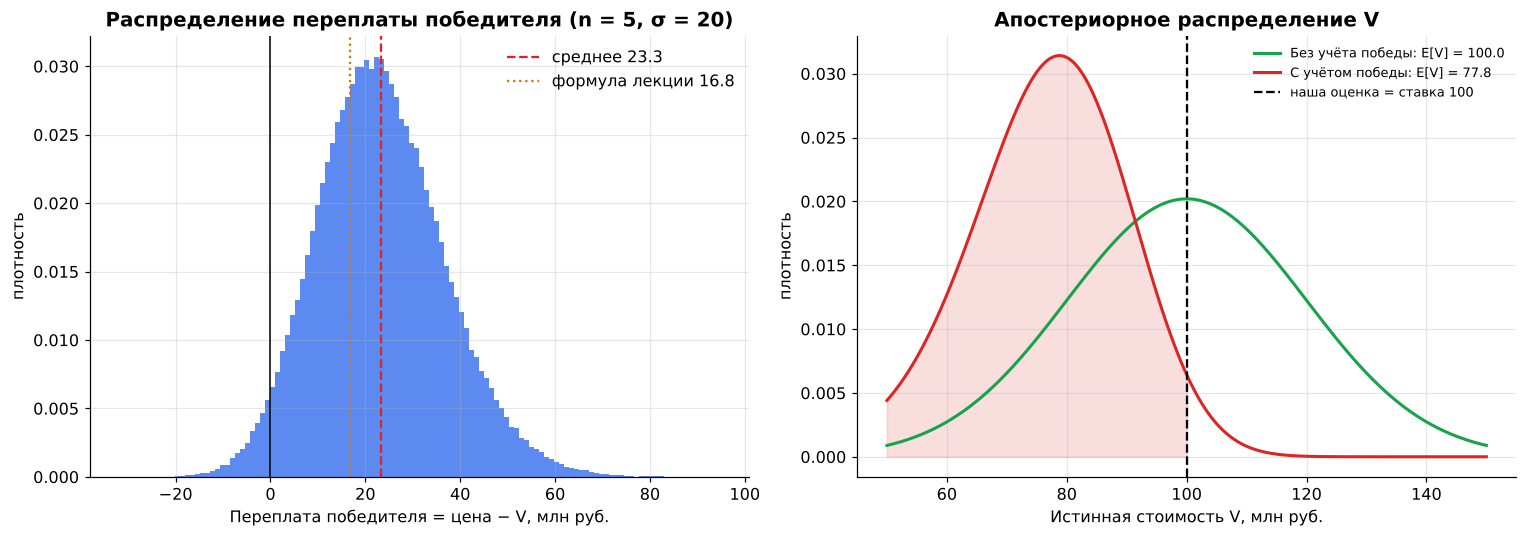

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.hist(overpay, bins=120, density=True, color=PALETTE[0], alpha=0.75)
ax.axvline(0, color="black", lw=1); ax.axvline(overpay.mean(), color=PALETTE[1], ls="--", label=f"среднее {overpay.mean():.1f}")
ax.axvline(sigma * norm.ppf(1 - 1 / n), color=PALETTE[3], ls=":", label=f"формула лекции {sigma*norm.ppf(1-1/n):.1f}")
ax.set_xlabel("Переплата победителя = цена − V, млн руб."); ax.set_ylabel("плотность")
ax.set_title(f"Распределение переплаты победителя (n = {n}, σ = {sigma})"); ax.legend()
ax = axes[1]
for label, w, c in [("Без учёта победы", False, PALETTE[2]), ("С учётом победы", True, PALETTE[1])]:
    d = posterior(grid, win=w); d /= np.trapezoid(d, grid)
    ax.plot(grid, d, lw=2, color=c, label=f"{label}: E[V] = {np.trapezoid(grid*d, grid):.1f}")
ax.axvline(x_own, color="black", ls="--", label="наша оценка = ставка 100")
ax.fill_between(grid, 0, posterior(grid) / np.trapezoid(posterior(grid), grid), where=grid < x_own, color=PALETTE[1], alpha=0.15)
ax.set_xlabel("Истинная стоимость V, млн руб."); ax.set_ylabel("плотность"); ax.set_title("Апостериорное распределение V")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

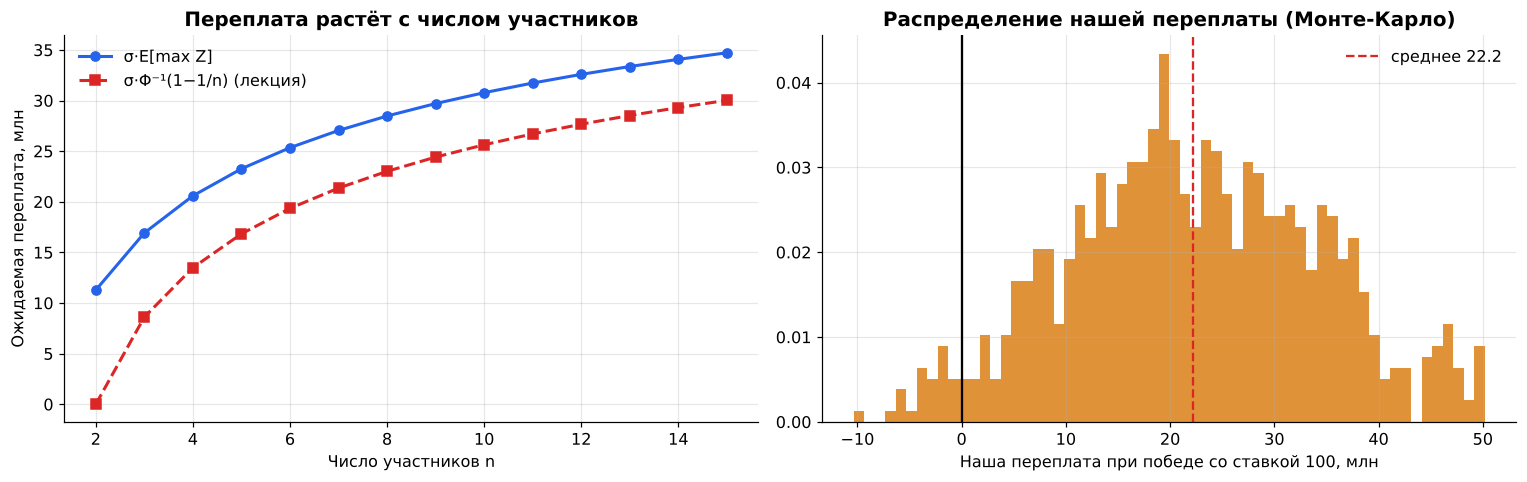

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ns = range(2, 16)
ax.plot(list(ns), [sigma * integrate.quad(lambda z, k=k: z * k * norm.pdf(z) * norm.cdf(z) ** (k - 1), -10, 10)[0] for k in ns], "o-", lw=2, label="σ·E[max Z]")
ax.plot(list(ns), [sigma * norm.ppf(1 - 1 / k) for k in ns], "s--", lw=2, label="σ·Φ⁻¹(1−1/n) (лекция)")
ax.set_xlabel("Число участников n"); ax.set_ylabel("Ожидаемая переплата, млн"); ax.set_title("Переплата растёт с числом участников")
ax.legend()
ax = axes[1]
own_over = (own - V)[mask]
ax.hist(own_over, bins=60, color=PALETTE[3], alpha=0.8, density=True)
ax.axvline(0, color="black"); ax.axvline(own_over.mean(), color=PALETTE[1], ls="--", label=f"среднее {own_over.mean():.1f}")
ax.set_xlabel("Наша переплата при победе со ставкой 100, млн"); ax.set_title("Распределение нашей переплаты (Монте-Карло)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Победитель почти всегда переплачивает.** Если все ставят свои оценки, победитель переплачивает с вероятностью около 97 %,
  в среднем примерно на 23 млн руб. (около 25 % стоимости). Упрощённая формула лекции $\sigma\Phi^{-1}(1-1/n)$ даёт 16,8 млн,
  то есть занижает эффект. Точное значение $\sigma E[\max Z]\approx 23{,}3$ млн.
- **Наша ситуация.** Если рассуждать «наивно», оценка 100 млн несмещённая: шанс переплатить 50 %, средняя переплата 0.
  Но **сам факт победы** значит, что все 4 конкурента оценили стартап ниже нас, а значит, наша оценка, скорее всего, завышена.
  С учётом победы ожидаемая стоимость падает примерно до **78 млн руб.**: вероятность переплаты около **97 %**,
  средняя переплата около **22 млн руб.** (28 % цены). Монте-Карло (776 случаев, где оценка около 100 и мы выиграли)
  даёт те же цифры.
- **Распределение переплаты** сдвинуто вправо: почти всегда переплата положительная, а в хвосте больше 30–40 млн руб.
- **Поправка ставки.** Если конкуренты ставят свои оценки, ставка без ожидаемого убытка всего около 60 млн руб.
  (скидка около 40 % к оценке, а не 15 %, как в упрощённом правиле лекции). Но с такой ставкой мы почти никогда не выиграем:
  только когда все конкуренты сильно недооценили стартап, то есть когда он действительно дешёвый.
  Любая ставка от 70 до 100 млн руб. в среднем убыточна. Вывод: против «наивных» участников при σ = 20 млн руб.
  выиграть этот аукцион с выгодой почти невозможно.

## 7. Выводы и рекомендации

1. **Ответы на вопросы задачи:** при оценке 100 млн руб. и победе вероятность переплаты около 97 %, средняя переплата
   около 22 млн руб. У «среднего» победителя такого аукциона около 97 % и 23 млн руб. Распределение переплаты построено выше.
2. **Не ставить свою оценку.** Ставка 100 млн руб. почти гарантирует переплату. Ставка без ожидаемого убытка около 60 млн руб.,
   и шанс выиграть с ней маленький. Это нормально: разумный участник выигрывает только «дешёвые» аукционы.
3. **Уменьшать ошибку оценки σ:** провести проверку стартапа (финансы, технологии, команда, права на IP).
   Переплата пропорциональна σ: если ошибка в 2 раза меньше, переплата тоже в 2 раза меньше.
4. **Учитывать число конкурентов:** чем их больше, тем больше переплата (при 10 участниках примерно на 30 % больше, чем при 5).
5. **Заранее решить, где остановиться,** и не поднимать эту цену во время торгов.
6. **Правильно построить сделку:** часть оплаты после достижения KPI (earn-out) переносит риск ошибки на продавца.
   Если синергия для нас больше, чем для других, её надо считать отдельно от «общей» стоимости.